# infercnvpy

In [1]:
import scanpy as sc
import infercnvpy as cnv
import pandas as pd
import numpy as np

# 1. 读取你的 h5ad 文件
# 请将 "your_data.h5ad" 替换为你的实际文件名
adata = sc.read_h5ad("01.sc_annoted.h5ad")

# 查看一下数据概况


In [2]:
adata.var["gene_ids"] = adata.var.index

In [3]:
# 直接使用symbol查询小鼠基因组位置
cnv.io.genomic_position_from_biomart(
    adata=adata,
    adata_gene_id="gene_ids",
    biomart_gene_id="external_gene_name",  # 小鼠基因symbol
    species="mmusculus",
)

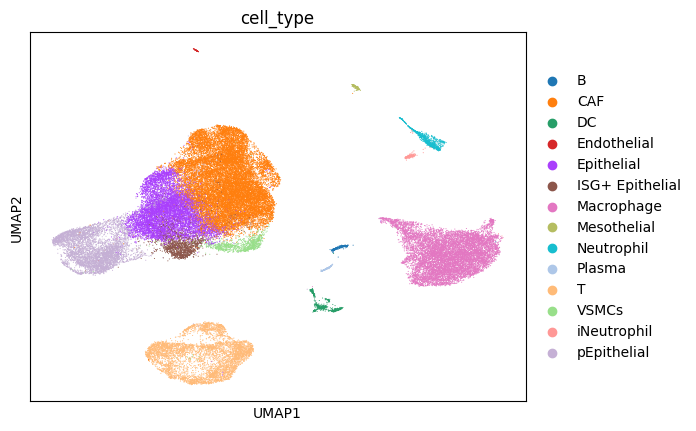

In [4]:
sc.pl.umap(adata, color="cell_type")

In [5]:
adata.obs["cell_type"].unique().tolist()



['CAF',
 'pEpithelial',
 'Macrophage',
 'T',
 'iNeutrophil',
 'DC',
 'B',
 'VSMCs',
 'Neutrophil',
 'ISG+ Epithelial',
 'Epithelial',
 'Endothelial',
 'Plasma',
 'Mesothelial']

In [6]:
# We provide all immune cell types as "normal cells".
cnv.tl.infercnv(
    adata,
    reference_key="cell_type",
    reference_cat=[
        "Macrophage",
        "T",
        "iNeutrophil",
        "DC",
        "B",
        "Neutrophil",
        "VSMCs",
        "Endothelial",
        "Plasma",
        "Mesothelial"
    ],
    window_size=250,
)


100%|██████████| 11/11 [00:12<00:00,  1.18s/it]


In [7]:
import matplotlib.pyplot as plt

In [10]:
cnv.pl.chromosome_heatmap(adata, groupby="cell_type", show=False)
plt.savefig("cnv_chromosome_heatmap_celltype.pdf", bbox_inches="tight", dpi=300)
plt.close()


In [12]:
cnv.tl.pca(adata)
cnv.pp.neighbors(adata)
cnv.tl.leiden(adata)


E:\miniforge\Lib\site-packages\infercnvpy\tl\__init__.py:24: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  return sc.tl.leiden(


E:\miniforge\Lib\site-packages\infercnvpy\pl\_chromosome_heatmap.py:74: UserWarning: You’re trying to run this on 1431 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  return_ax_dic = sc.pl.heatmap(


categories: 0, 1, 2, etc.
var_group_labels: chr1, chr2, chr3, etc.


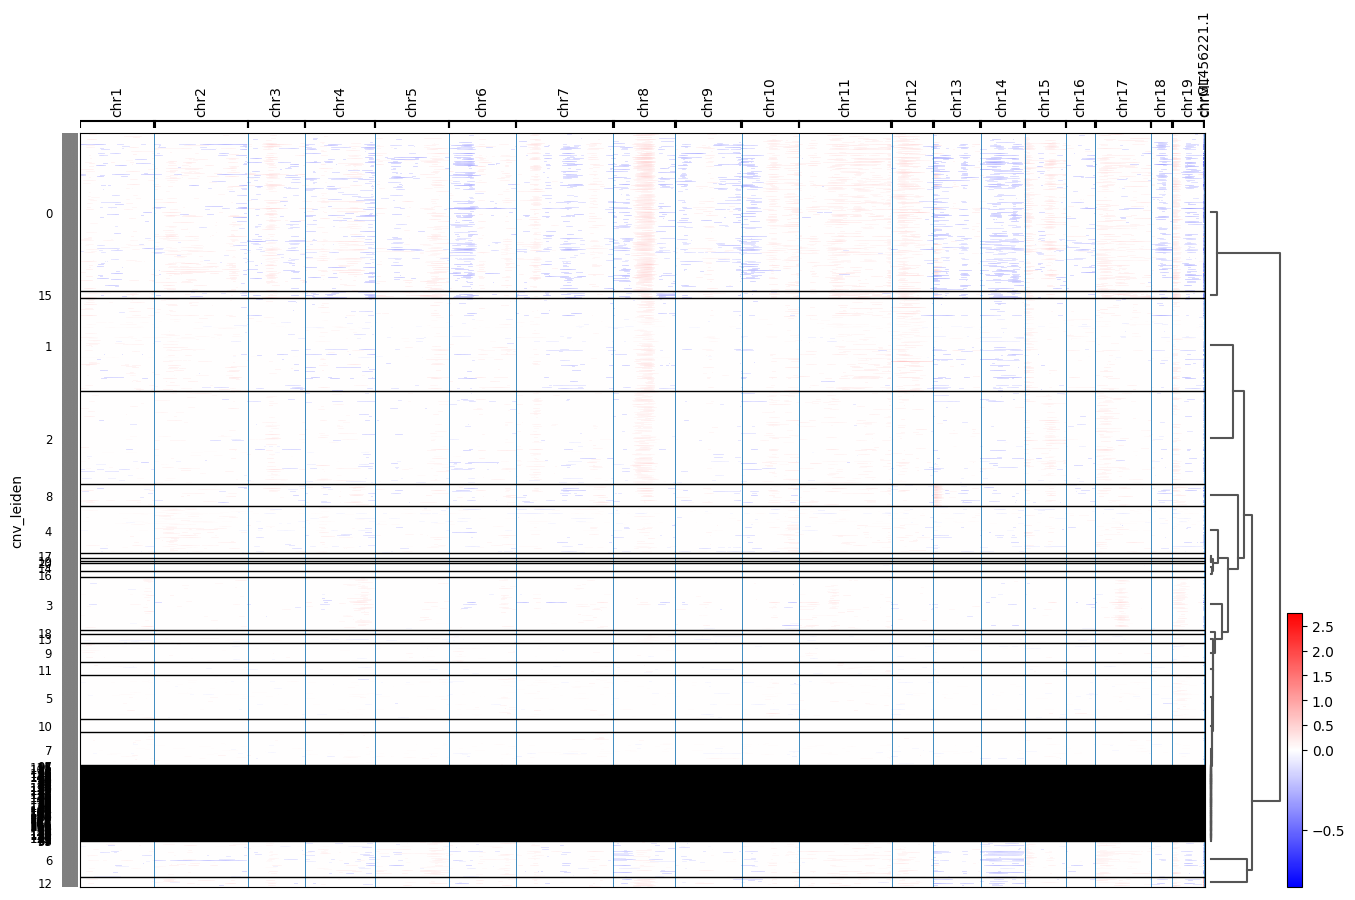

In [13]:
cnv.pl.chromosome_heatmap(adata, groupby="cnv_leiden", dendrogram=True)


In [14]:
cnv.tl.umap(adata)
cnv.tl.cnv_score(adata)


In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5))  # 一行两列

sc.pl.umap(adata, color="cnv_score", ax=ax1, show=False)
sc.pl.umap(adata, color="cell_type", ax=ax2, show=False)
plt.tight_layout()
plt.savefig("cnvumap.pdf", bbox_inches="tight", dpi=300)
plt.close()
